# Scénario S5 : C-MAPSS, des moteurs qui volent dans d'autres conditions

**La question.** Des turboréacteurs ont été suivis jusqu'à la panne, mais tous au même régime de vol (la source). Une nouvelle flotte vole à six régimes différents (la cible) et l'on n'y a étiqueté que quelques centaines de cycles. Le savoir appris sur la source aide-t-il à prédire une **panne dans les 30 cycles** sur la nouvelle flotte ? Avec quelles méthodes, et jusqu'à quel budget d'annotation ?

**Comment lire ce notebook.** Il ne relance pas l'expérience : il lit les résultats écrits par le moteur. Pour les produire, depuis la racine du dépôt :

```bash
python -m transfer_forest.run S5      # 20 graines, 11 méthodes, 5 budgets : environ 15 min
```

La section 6 compare S5 à S1 : elle demande aussi `python -m transfer_forest.run S1`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image

from transfer_forest.contracts import make_forest
from transfer_forest.data import load_scenarios
from transfer_forest.data.s5_cmapss import read
from transfer_forest.evaluation import evaluate
from transfer_forest.splits import split_target

RESULTS = Path("..") / "results"      # écrit par : python -m transfer_forest.run S5 (depuis la racine)
results = pd.read_csv(RESULTS / "S5.csv")
summary = pd.read_csv(RESULTS / "S5_summary.csv")

[scn] = load_scenarios("S5")
reserve, test = split_target(scn)
print(f"source : {scn.n_S} cycles ({len(np.unique(read('FD001').unit))} moteurs)   "
      f"cible : {len(scn.yt)} cycles ({len(np.unique(scn.groups_t))} moteurs)")
print(f"réserve : {len(reserve)} cycles, {len(np.unique(scn.groups_t[reserve]))} moteurs   "
      f"test : {len(test)} cycles, {len(np.unique(scn.groups_t[test]))} moteurs")
print(f"part de cycles « panne » : source {scn.ys.mean():.3f}, cible {scn.yt.mean():.3f}")

source : 20631 cycles (100 moteurs)   cible : 53759 cycles (260 moteurs)
réserve : 27080 cycles, 130 moteurs   test : 26679 cycles, 130 moteurs
part de cycles « panne » : source 0.150, cible 0.150


## 1. Le scénario

Chaque exemple est un **cycle de vol** d'un moteur : 3 réglages de vol (altitude, Mach, poussée) et 21 capteurs. L'étiquette vaut « panne » si le moteur tombe en panne dans les 30 cycles suivants (durée de vie restante $\le 30$).

- **Source** : FD001, 100 moteurs, **un seul régime** de vol (niveau de la mer).
- **Cible** : FD002, 260 moteurs, **six régimes** de vol. Même panne (usure du compresseur haute pression).
- **Note principale : la BER**, $\frac12(\text{part des pannes ratées} + \text{part des fausses alertes})$. Avec 15 % de cycles « panne », répondre toujours « sain » donne 15 % d'erreur mais une BER de 50 % : seule la BER voit qu'on rate toutes les pannes.
- **Découpage par moteur** : chaque moteur va entier dans le test ou dans la réserve. Sinon, une méthode serait notée sur des cycles presque identiques à ceux qu'elle a appris.

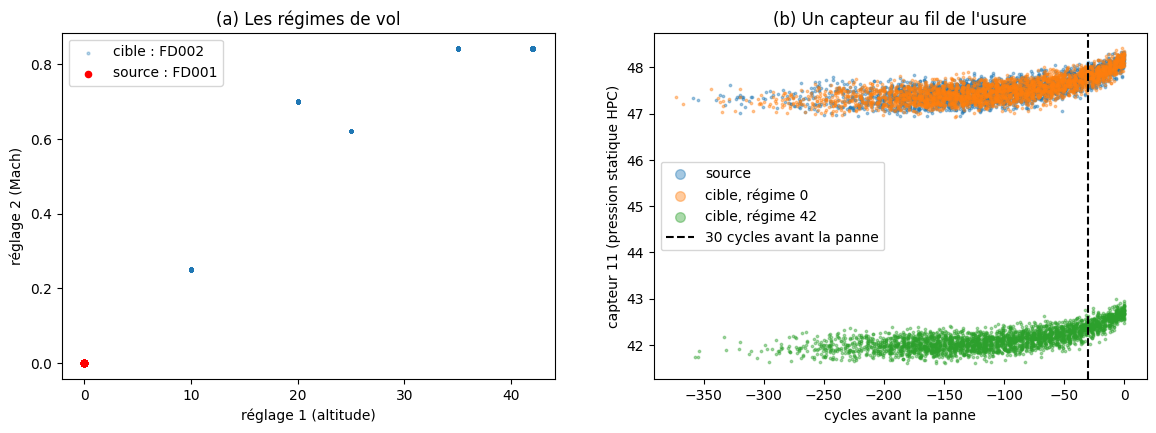

In [2]:
source, target = read("FD001"), read("FD002")
target["regime"] = target["setting1"].round().astype(int)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.scatter(target.setting1, target.setting2, s=4, alpha=0.3, label="cible : FD002")
ax1.scatter(source.setting1, source.setting2, s=20, color="red", label="source : FD001")
ax1.set(xlabel="réglage 1 (altitude)", ylabel="réglage 2 (Mach)", title="(a) Les régimes de vol")
ax1.legend()

for name, df in [("source", source), ("cible, régime 0", target[target.regime == 0]),
                 ("cible, régime 42", target[target.regime == 42])]:
    d = df.sample(3000, random_state=0)
    ax2.scatter(-d.rul, d.sensor11, s=3, alpha=0.4, label=name)
ax2.axvline(-30, color="k", ls="--", label="30 cycles avant la panne")
ax2.set(xlabel="cycles avant la panne", ylabel="capteur 11 (pression statique HPC)",
        title="(b) Un capteur au fil de l'usure")
ax2.legend(markerscale=4)
plt.show()

**(a)** Les moteurs source volent tous au même point (en rouge) ; la cible occupe six points, dont un seul est celui de la source. **(b)** Le capteur 11 monte avec l'usure, de la même façon dans les deux domaines : c'est la même panne. Mais au régime 42, toutes ses valeurs sont décalées, bien au-delà de ce que produit l'usure. Un modèle appris au niveau de la mer ne peut pas les lire.

## 2. Le décalage, mesuré

Trois mesures du protocole, calculées sur la réserve : l'AUC d'une forêt qui devine le domaine (0,5 : indiscernables ; 1 : séparables), l'écart des proportions de classes, et l'écart de domaine (BER de la forêt source sur la cible moins sa BER hors sac sur la source).

In [3]:
pd.read_csv(RESULTS / "S5_shift.csv").T

,0
scenario,S5
auc_domain,0.995357
auc_domain_sd,0.000028
auc_domain_excl,NaN
prop_gap,0.001441
domain_gap,0.347187
n_S,20631
n_target,53759
K,2
d,24


In [4]:
rf = make_forest(0).fit(scn.Xs, scn.ys)                  # la forêt source de la graine 0
regime = scn.Xt[test, 0].round().astype(int)
P = rf.predict_proba(scn.Xt[test])
ber = {r: evaluate(scn.yt[test][regime == r], P[regime == r])["ber"] for r in np.unique(regime)}
leaves = rf.estimators_[0].apply(scn.Xt[test].astype(np.float32))
print("feuilles du 1er arbre source atteintes : régime 0 :", len(np.unique(leaves[regime == 0])),
      "  cinq autres régimes :", len(np.unique(leaves[regime != 0])))
pd.Series(ber, name="BER de Src").rename_axis("régime").round(3).to_frame().T

feuilles du 1er arbre source atteintes : régime 0 : 305   cinq autres régimes : 2


régime,0,10,20,25,35,42
BER de Src,0.104,0.5,0.5,0.5,0.5,0.5


**Lecture.**
- Les domaines sont presque parfaitement séparables (AUC de 0,995), mais **les proportions de classes ne changent pas** (écart de 0,001). C'est un décalage des covariables pur, l'inverse de S1 où les proportions de lettres changeaient fortement.
- La forêt source perd **35 points de BER** en passant sur la cible. Régime par régime, elle est bonne sur le régime commun (BER de 0,10) et **au hasard (0,50) sur les cinq autres**.
- La raison est visible dans les arbres : les cycles des cinq régimes inconnus tombent dans **deux feuilles seulement** d'un arbre source. Hors du support de ses données, une forêt n'extrapole pas, elle répond toujours la même chose.

## 3. Les notes

BER moyenne sur les 20 graines, selon le nombre $n_T$ de cycles cibles étiquetés (206 à 4 126). Src et Oracle ne dépendent pas du budget.

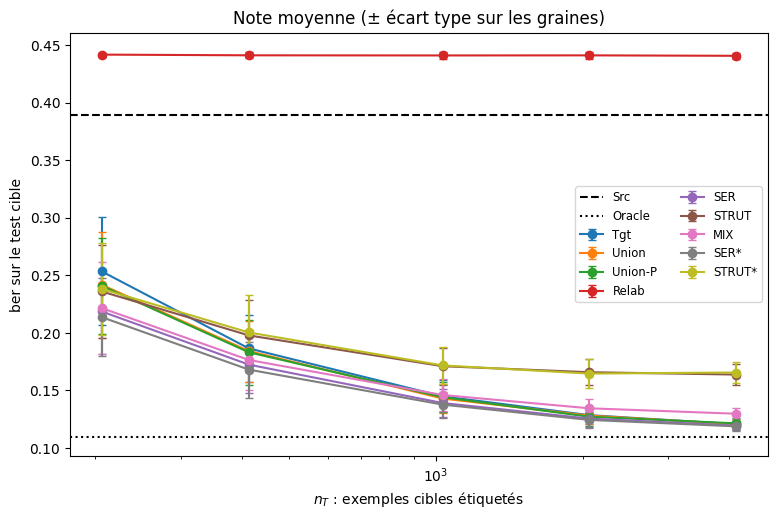

In [5]:
Image(RESULTS / "S5_scores.png")

In [6]:
def by_budget(note):
    """Moyenne sur les 20 graines, par méthode et budget ; Src et Oracle dans « sans budget »."""
    t = results.fillna({"n_T": 0}).pivot_table(index="method", columns="n_T", values=note, aggfunc="mean")
    return t.rename(columns={0: "sans budget"}).round(3)

by_budget("ber")

n_T,sans budget,206.0,413.0,1032.0,2063.0,4126.0
method,,,,,,
MIX,NaN,0.221,0.176,0.146,0.134,0.130
Oracle,0.110,NaN,NaN,NaN,NaN,NaN
Relab,NaN,0.442,0.441,0.441,0.441,0.441
SER,NaN,0.219,0.172,0.139,0.126,0.119
SER*,NaN,0.214,0.168,0.138,0.124,0.119
STRUT,NaN,0.236,0.198,0.171,0.166,0.164
STRUT*,NaN,0.238,0.200,0.172,0.165,0.166
Src,0.389,NaN,NaN,NaN,NaN,NaN
Tgt,NaN,0.253,0.186,0.145,0.129,0.121


**Lecture.** Trois familles de comportement :
- **SER et SER\*** sont les meilleures méthodes à tous les budgets : BER de 0,214 (SER\*) contre 0,253 pour Tgt à 206 cycles, et elles rejoignent ensuite Tgt (0,119 contre 0,121 à 4 126).
- **Union et Union-P** collent à Tgt : la source ne leur apporte presque rien.
- **STRUT, STRUT\* et Relab** font moins bien que Tgt. Relab reste bloquée à 0,44 quel que soit le budget, presque au niveau de la forêt source.

## 4. Les gains : réels ou dus au hasard ?

Gains appariés graine par graine, en points de BER. $G_{Tgt}$ : par rapport à Tgt. $G_{ref}$ : par rapport à la meilleure de Src, Tgt et Union (définition du protocole ; Union-P est jugée comme une méthode). L'étoile indique un gain significatif : test de Wilcoxon apparié sur les 20 graines, corrigé par Holm sur les 5 budgets.

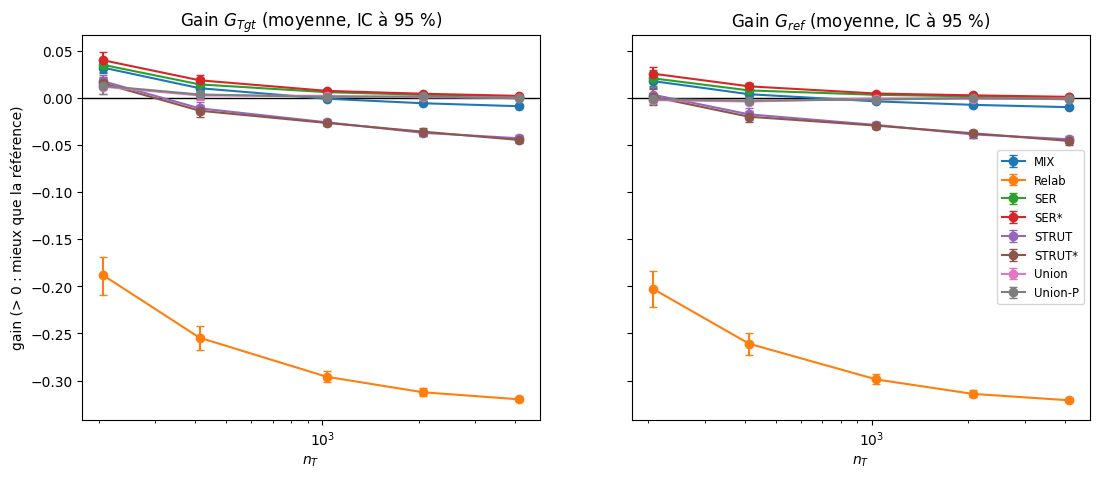

In [7]:
Image(RESULTS / "S5_gains.png")

Relab écrase l'échelle de la figure (−19 à −32 points) ; les tableaux ci-dessous donnent le détail des autres méthodes.

In [8]:
def with_stars(gain):
    """Gain moyen en points de BER ; * : significatif (Wilcoxon, Holm, 5 %)."""
    s = summary.assign(cell=lambda d: (100 * d[f"{gain}_mean"]).round(1).astype(str)
                       + np.where(d[f"{gain}_p_holm"] < 0.05, " *", ""))
    return s.pivot(index="method", columns="n_T", values="cell").drop(index=["Src", "Tgt", "Oracle"])

print("G_Tgt (points de BER gagnés sur Tgt)")
display(with_stars("g_tgt"))
print("G_ref (points de BER gagnés sur la meilleure de Src, Tgt, Union)")
display(with_stars("g_ref"))

G_Tgt (points de BER gagnés sur Tgt)


n_T,206.0,413.0,1032.0,2063.0,4126.0
method,,,,,
MIX,3.2 *,1.0 *,-0.1,-0.6 *,-0.9 *
Relab,-18.8 *,-25.5 *,-29.6 *,-31.2 *,-32.0 *
SER,3.5 *,1.4 *,0.6 *,0.3 *,0.1 *
SER*,4.0 *,1.8 *,0.7 *,0.4 *,0.2 *
STRUT,1.7 *,-1.1 *,-2.6 *,-3.7 *,-4.3 *
STRUT*,1.5 *,-1.4 *,-2.7 *,-3.6 *,-4.5 *
Union,1.2,0.2,0.2,0.0,-0.0
Union-P,1.2,0.3,0.1,0.1,-0.1


G_ref (points de BER gagnés sur la meilleure de Src, Tgt, Union)


n_T,206.0,413.0,1032.0,2063.0,4126.0
method,,,,,
MIX,1.8 *,0.4,-0.4 *,-0.8 *,-1.0 *
Relab,-20.3 *,-26.1 *,-29.9 *,-31.4 *,-32.1 *
SER,2.1 *,0.8 *,0.3 *,0.1,0.0
SER*,2.5 *,1.2 *,0.4 *,0.2 *,0.1
STRUT,0.3,-1.8 *,-2.9 *,-3.9 *,-4.4 *
STRUT*,0.1,-2.0 *,-3.0 *,-3.8 *,-4.6 *
Union,-0.3 *,-0.4 *,-0.1 *,-0.1 *,-0.1 *
Union-P,-0.2,-0.3,-0.2,-0.0,-0.2 *


In [9]:
synth = summary.pivot(index="method", columns="n_T", values="saving").round(2)
synth["budget de croisement"] = summary.groupby("method")["crossover_n_T"].first()
synth.drop(index=["Src", "Tgt", "Oracle"])

n_T,206.0,413.0,1032.0,2063.0,4126.0,budget de croisement
method,,,,,,
MIX,1.39,1.25,0.98,0.78,0.47,1032.0
Relab,NaN,NaN,NaN,NaN,NaN,206.0
SER,1.44,1.36,1.28,1.30,NaN,NaN
SER*,1.51,1.50,1.36,1.44,NaN,NaN
STRUT,1.20,0.89,0.56,0.32,0.17,413.0
STRUT*,1.17,0.87,0.55,0.32,0.16,413.0
Union,1.13,1.05,1.08,1.04,1.00,206.0
Union-P,1.14,1.08,1.03,1.13,0.94,206.0


**Lecture.**
- **SER\*** gagne sur Tgt de façon significative à tous les budgets : +4,0 points à 206 cycles (20 graines sur 20), +1,8 à 413, puis +0,7, +0,4 et +0,2. Son économie d'annotation est d'environ 1,5 : avec 206 cycles, elle fait ce que Tgt fait avec 300. Elle bat aussi la meilleure référence ($G_{ref}$) jusqu'à 2 063 cycles.
- **Significatif ne veut pas dire important.** À 4 126 cycles, un gain de 0,2 point est statistiquement solide (20 graines appariées), mais sans intérêt pratique. La valeur du transfert est concentrée sur les **petits budgets**.
- **MIX** gagne aux deux plus petits budgets, puis perd : STRUT, qui compose la moitié de la forêt, la tire vers le bas.
- **STRUT** ne gagne qu'à 206 cycles (+1,7 point), puis fait du **transfert négatif** de plus en plus marqué (−4,3 points à 4 126). **Relab** perd de 19 à 32 points à tous les budgets.
- **Union-P** ne bat jamais Tgt de façon significative, alors qu'elle était la meilleure méthode sur S1.

## 5. Ce qui compte pour l'exploitation : les pannes ratées et le coût

Part des cycles « panne » non détectés (`fnr_critical`).

In [10]:
by_budget("fnr_critical")

n_T,sans budget,206.0,413.0,1032.0,2063.0,4126.0
method,,,,,,
MIX,NaN,0.429,0.339,0.277,0.253,0.244
Oracle,0.200,NaN,NaN,NaN,NaN,NaN
Relab,NaN,0.881,0.880,0.880,0.880,0.879
SER,NaN,0.418,0.327,0.259,0.232,0.220
SER*,NaN,0.409,0.318,0.257,0.229,0.218
STRUT,NaN,0.460,0.384,0.331,0.321,0.318
STRUT*,NaN,0.465,0.389,0.332,0.319,0.321
Src,0.376,NaN,NaN,NaN,NaN,NaN
Tgt,NaN,0.494,0.358,0.272,0.238,0.223


In [11]:
results.groupby("method")[["t_fit", "t_predict"]].mean().round(2).sort_values("t_fit")

,t_fit,t_predict
method,,
Src,0.00,0.25
Tgt,0.60,0.26
Relab,2.84,2.52
SER*,4.24,2.24
Union,4.91,0.28
SER,4.91,2.61
Union-P,5.39,0.29
Oracle,9.65,0.62
STRUT*,11.35,1.47


**Lecture.**
- À 206 cycles étiquetés, Tgt rate **49 %** des pannes, SER\* **41 %** : 8 points de pannes manquées en moins. L'écart se résorbe ensuite (22 % pour les deux à 4 126).
- Le taux d'erreur brut raconterait une autre histoire : STRUT a un taux d'erreur proche de celui de SER à 206 cycles (7,9 %), mais rate 46 % des pannes. C'est exactement pour cela que la BER est la note principale.
- **Le coût** : SER s'apprend en environ 5 s contre 0,6 s pour Tgt, et prédit dix fois plus lentement (2,6 s contre 0,26 s pour 26 700 cycles) : notre implémentation parcourt les arbres en Python, là où scikit-learn le fait en C. MIX coûte le plus (15 s) puisqu'elle apprend SER et STRUT.

## 6. S5 face à S1 : un autre décalage, une autre réponse

Gain moyen sur Tgt ($G_{Tgt}$, en points de la note principale) au plus petit et au plus grand budget de chaque scénario.

In [12]:
def gains_at_extremes(name):
    s = pd.read_csv(RESULTS / f"{name}_summary.csv")
    s = s[~s.method.isin(["Src", "Tgt", "Oracle"])]
    lo, hi = s.n_T.min(), s.n_T.max()
    pick = lambda n: s[s.n_T == n].set_index("method")["g_tgt_mean"] * 100
    return pd.DataFrame({f"{name}, n_T = {lo:.0f}": pick(lo), f"{name}, n_T = {hi:.0f}": pick(hi)})

pd.concat([gains_at_extremes("S1"), gains_at_extremes("S5")], axis=1).round(1)   # G_Tgt, en points

,"S1, n_T = 108","S1, n_T = 2164","S5, n_T = 206","S5, n_T = 4126"
method,,,,
MIX,7.0,1.3,3.2,-0.9
Relab,7.5,-1.7,-18.8,-32.0
SER,7.2,1.4,3.5,0.1
SER*,8.6,1.4,4.0,0.2
STRUT,0.3,-2.7,1.7,-4.3
STRUT*,0.5,-2.6,1.5,-4.5
Union,2.2,1.3,1.2,-0.0
Union-P,9.2,1.6,1.2,-0.1


**Lecture.** Les deux scénarios donnent presque des classements opposés :

| | S1 (Letter) | S5 (C-MAPSS) |
|---|---|---|
| Décalage | domaines **voisins** (lettres étroites ou étalées), proportions de classes très changées | **cinq régions sur six inconnues** de la source, proportions inchangées |
| Meilleure méthode | **Union-P** (+9,2 points à 108 exemples) | **SER\*** (+4,0 points à 206 cycles) |
| Union-P | gain significatif à tous les budgets | aucun gain significatif |
| Relab | +7,5 points à petit budget | −19 à −32 points |
| STRUT | rien, puis transfert négatif | +1,7 point à 206, puis transfert négatif |

- **Sur S1**, les exemples source sont **proches** de la cible : une lettre étroite renseigne sur une lettre un peu plus large. Ajouter les données source, en rééquilibrant leur poids (Union-P), suffit.
- **Sur S5**, les exemples source ne renseignent que sur **un régime sur six** : les ajouter n'apprend rien sur les cinq autres. Ce qui aide, c'est de garder le **modèle** source là où il est valable (le régime commun) et de faire pousser une structure nouvelle là où il n'a rien vu. C'est exactement ce que fait SER : l'expansion greffe des arbres appris sur la cible sous les feuilles où tombent les régimes inconnus.
- Les méthodes qui **conservent la structure source** (Relab, STRUT) échouent dès que la cible sort du support de la source : leur partition ne contient aucune distinction utile là où vit la cible.

## 7. Bilan : quand le transfert a-t-il de la valeur ?

1. **Le transfert a une valeur réelle mais limitée aux petits budgets.** Sur S5, SER\* rate 8 points de pannes en moins que Tgt avec 206 cycles étiquetés, et économise environ un tiers des annotations. Au-delà d'environ 1 000 cycles, les gains restent statistiquement significatifs mais inférieurs à 1 point : apprendre sur la cible seule suffit.
2. **La bonne méthode dépend du type de décalage**, et l'on peut le diagnostiquer avant d'étiqueter quoi que ce soit :
   - si la cible est **proche** de la source (support voisin ou commun) : réutiliser les **données** source (Union-P) ;
   - si la cible contient des **régions que la source n'a jamais vues** : réutiliser le **modèle** source là où il est valable et le laisser s'étendre ailleurs (SER, SER\*) ;
   - éviter les méthodes qui **figent la structure source** (Relab, STRUT) dans ce second cas : transfert négatif garanti.
3. **Un diagnostic simple avant de choisir** : l'AUC du classifieur de domaine dit si les domaines sont séparables ; la part de la cible qui tombe dans des régions déjà couvertes par la source (ici, le régime commun, 15 %) dit si la structure source a une chance de servir.
4. **Lire la bonne note** : en taux d'erreur, STRUT paraît aussi bon que SER ; en BER et en pannes ratées, il est nettement moins bon.

**Limites.** Un exemple est un cycle isolé (pas de fenêtre temporelle) ; le budget est compté en cycles, et non en moteurs suivis jusqu'à la panne ; la normalisation par régime de vol, qui rapprocherait les domaines, n'est pas testée : c'est une méthode de transfert à part entière (famille F de l'état de l'art), une bonne candidate pour la suite.